In [1]:
import pandas as pd
import numpy as np
import json
import rapidfuzz
from random import choice
from matplotlib import pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
from sys import path as sys_path
project_root = Path.cwd().parent.parent
if project_root not in sys_path:
    sys_path.append(str(project_root))

In [3]:
data_dir = project_root/"data/"
outputs_dir = project_root/"outputs/"

## Loading data

In [4]:
events_json = (
    outputs_dir/"json/all_migration_events_parish_splits/"
    "395_migration_events.jsonl"
)

with open(events_json, "r") as fp:
    lines = list(
        json.loads(json_line)
        for json_line in fp
    )

In [5]:
print_columns_df = pd.read_csv(outputs_dir/"csv/print_type_columns.csv")
print_columns_df = print_columns_df.rename(
    {"print type": "print_type", "sarakkeet": "column"}, axis="columns"
)
print_columns_df["column"] = print_columns_df["column"].apply(
    lambda cols: json.loads(cols.replace("'", '"'))
)
print_columns_df = print_columns_df.explode("column").reset_index(drop=True)

In [6]:
print_columns_df["column_idx"] = print_columns_df.groupby("print_type").cumcount()

In [7]:
with open(outputs_dir/"json/print_type_column_names_categorized.json", "r") as fp:
    print_column_name_to_categorized = json.load(fp)

In [8]:
print_columns_df["column_categorized"] = print_columns_df["column"].apply(
    print_column_name_to_categorized.get
)

## Finding toponym columns

Idea: search cell strings from list of toponyms. Columns that contain toponyms
should have the best matches.

In [9]:
chosen_page = list(
    filter(
        lambda x: (
            x["page_n"] == 1
            and x["side"] == "both"
            and x["book"] == "pielavesi_muuttaneet_1881-1887_mko44-45"
        ),
        lines
    )
)

page_data = []
for row in chosen_page:
    page_data.append(row["row_data"])
    prev_page = row["page_n"]

In [10]:
def transpose_page_table(page_data):
    n_columns = max(map(len, page_data))
    page_cols = []
    for col in range(n_columns):
        page_cols.append(
            [
                row[col] if len(row) > col else ""
                for row in page_data
            ]
        )
    return page_cols

page_cols = transpose_page_table(page_data)

In [11]:
with open(data_dir/"kohde_split.txt", "r") as fp:
    valid_toponyms = set(toponym.replace("\n", "") for toponym in fp.readlines())

with open(outputs_dir/"json/db_toponyms.json", "r") as fp:
    valid_toponyms = valid_toponyms.union(
        set(json.load(fp).keys())
    )

In [12]:
def column_match_scores(
    column,
    choices,
    scorer=rapidfuzz.distance.Levenshtein.normalized_similarity,
    return_scores_only=True,
    scorer_kwargs=None
):
    column_match_scores = []
    for cell in column:
        cell_score = rapidfuzz.process.extractOne(
            cell,
            choices,
            scorer=scorer,
            scorer_kwargs=scorer_kwargs
        )

        if cell_score:
            column_match_scores.append(
                cell_score[1] if return_scores_only else cell_score
            )
        else:
            column_match_scores.append(
                0.0 if return_scores_only else (None, 0.0, np.nan)
            )

    return column_match_scores

In [13]:
print_columns_df[print_columns_df["print_type"] == f"print {chosen_page[0]["print_type"]}"].set_index(
    "column_idx"
)[["column", "column_categorized"]]

,column,column_categorized
column_idx,,
0,kuukausi,other
1,päivä,other
2,muuttokirjan numero,other
3,nimi ja sääty,name
4,miespuoli,person_count
5,naispuoli,person_count
6,(syntymä)päivä,other
7,(syntymä)paikka,place
8,empty,


Index 7 is the place a person was born in and index 10 is the place the person
moved to (column 8 "empty" doesn't exist in csv data).

Would expect index 7 or 10. The process is maybe thrown off by empty values:

In [14]:
print(*page_data[:5], sep="\n")

['Tammikuun', '2.', '1.', 'Poika Johanna Watanen', '', '1.', '30/5 1862', 'Pielavalellä', 'Naimaton', 'Työnteko', 'Kuopioon', '301.', 'Hyvämäininen.']
['"', '3.', '2', 'Erika Tikkanen', '', '1', '1863.', '"', '"', '1', 'Määnika', '459.459', '']
['"', '4', '3.', 'Työm:poika Paavo Ruotsalainen', '1.', '', '1864', '"', '"', '"', 'Kuopioon', '955 L', '']
['"', '9.', '4.', 'Talontr. Wiljolmiä Räisänen', '-', '1.', '1862.', '1o', '"', '"', '1o', '691.', '']
['"', '11', '5.', 'Renki Petter Auvinen', '1', '', '1852.', '"', '"', '"', '"', '670.', 'Sakertettu viinan myönnistä']


It's likely that the `"` values here mean that the previous value should be
repeated, at least for dates and placenames.

In [15]:
def fill_values(column, cells_to_replace={'"', '1o'}):
    filled_cells = []
    last_value = None
    for cell in column:
        if cell == "":
            filled_cells.append(cell)
        elif cell in cells_to_replace and last_value is not None:
            index = len(filled_cells) - 1
            while index >= 0 and filled_cells[index] == "":
                filled_cells[index] = last_value
                index -= 1
            filled_cells.append(last_value)
        else:
            filled_cells.append(cell)
            if cell not in cells_to_replace:
                last_value = cell

    return filled_cells

filled = fill_values(page_cols[7])
for i, (c, f) in enumerate(zip(page_cols[7], filled)):
    print(c, "->", f)

Pielavalellä -> Pielavalellä
" -> Pielavalellä
" -> Pielavalellä
1o -> Pielavalellä
" -> Pielavalellä
" -> Pielavalellä
" -> Pielavalellä
" -> Pielavalellä
 -> Pielavalellä
 -> Pielavalellä
 -> Pielavalellä
" -> Pielavalellä
Iisalmella -> Iisalmella
Pielavedellä -> Pielavedellä
 -> Pielavedellä
" -> Pielavedellä
 -> Pielavedellä
" -> Pielavedellä
 -> 
 -> 
 -> 
 -> 
 -> 
 -> 
 -> 
 -> 
 -> 
 -> 


In [16]:
levenshtein_scorer = rapidfuzz.distance.Levenshtein.normalized_similarity
jarowinkler_scorer = rapidfuzz.distance.JaroWinkler.normalized_similarity

columns_toponym_scores_levenshtein = [
    column_match_scores(
        fill_values(col), valid_toponyms, scorer=levenshtein_scorer
    )
    for col in page_cols
]
columns_toponym_scores_jarowinkler = [
    column_match_scores(
        fill_values(col), valid_toponyms, scorer=jarowinkler_scorer
    )
    for col in page_cols
]

column_average_scores_levenshtein = [
    np.mean(col) for col in columns_toponym_scores_levenshtein
]
column_average_scores_jarowinkler = [
    np.mean(col) for col in columns_toponym_scores_jarowinkler
]

With Levenshtein: [10  0  8  9  7  3  1 11  2  6  5  4 12]
With Jaro-Winkler: [10  0  9  8  3  7  1 11  6  5  2  4 12]


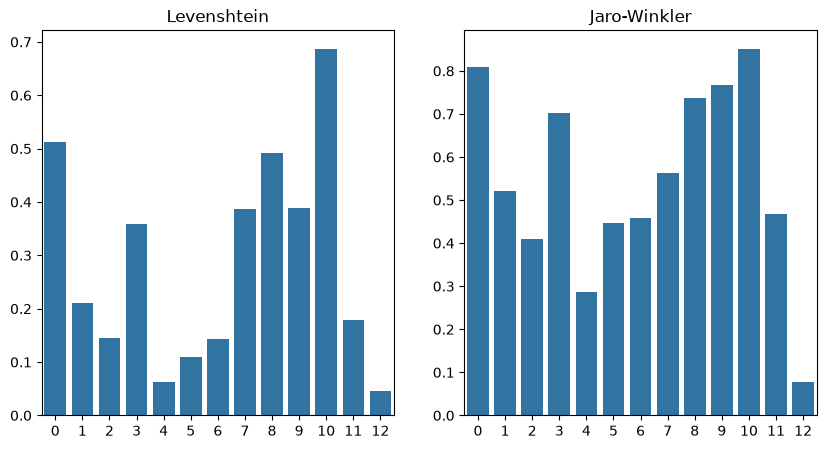

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
sns.barplot(column_average_scores_levenshtein, ax=axs[0])
sns.barplot(column_average_scores_jarowinkler, ax=axs[1])

axs[0].set_title("Levenshtein")
axs[1].set_title("Jaro-Winkler")

print("With Levenshtein:", np.argsort(column_average_scores_levenshtein)[::-1])
print("With Jaro-Winkler:", np.argsort(column_average_scores_jarowinkler)[::-1])

The Levenshtein seems to be the better metric to use here since it gives
a bigger difference between the toponym columns and the others.

Now the column at index 10 is correctly detected as place name column, but the
next best column should be 7, not 8 and columns 0 and 9 are uncomfortably close to the correct ones.

In [18]:
print("index 0", list(filter(bool, page_cols[0])))
print("index 8", list(filter(bool, page_cols[8])))
print("index 9", list(filter(bool, page_cols[9])))

index 0 ['Tammikuun', '"', '"', '"', '"', '"', '"', '"', 'Helmikuu', '"', '"', '"', '"', '"', '"', 'Maaliskun', '"', '"', '"', '"', '"']
index 8 ['Naimaton', '"', '"', '"', '"', 'nainut.', '"', '"', 'naimaton', '"', '"', 'Nainut', '"', 'Leski', 'Naimaton', '"', 'Nainut', '"', 'naimaton', 'nainut', 'Naimaton', '"', 'Leski', 'Naimit.', 'Naimaton', 'Nainut', 'Naimaton']
index 9 ['Työnteko', '1', '"', '"', '"', 'Kaupanteko.', 'Työnteko', '"', '"', '"', '"', '"', '"', '"', '"', '"', '"', '"', '"', '"', '"']


These types of mistakes found for example in column 12 look like they will be
sorted out by using a weighted Levenshtein:

In [19]:
col = 0
filled_col = fill_values(page_cols[col])
for i, match in enumerate(
    column_match_scores(
        filled_col,
        valid_toponyms,
        scorer=levenshtein_scorer,
        return_scores_only=False,
    )
):
    print(filled_col[i], "->", match)

Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Tammikuun -> ('Tammisaari', 0.5, 446)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Helmikuu -> ('Haliko', 0.5, 29)
Maaliskun -> ('Masku', 0.5555555555555556, 474)
Maaliskun -> ('Masku', 0.5555555555555556, 474)
Maaliskun -> ('Masku', 0.5555555555555556, 474)
Maaliskun -> ('Masku', 0.5555555555555556, 474)
Maaliskun -> ('Masku', 0.5555555555555

In [20]:
col = 8
filled_col = fill_values(page_cols[col])
for i, match in enumerate(
    column_match_scores(
        filled_col,
        valid_toponyms,
        scorer=levenshtein_scorer,
        return_scores_only=False,
    )
):
    print(filled_col[i], "->", match)

Naimaton -> ('Kimito', 0.5, 72)
Naimaton -> ('Kimito', 0.5, 72)
Naimaton -> ('Kimito', 0.5, 72)
Naimaton -> ('Kimito', 0.5, 72)
Naimaton -> ('Kimito', 0.5, 72)
nainut. -> ('Hailuoto', 0.5, 416)
nainut. -> ('Hailuoto', 0.5, 416)
nainut. -> ('Hailuoto', 0.5, 416)
naimaton -> ('Kimito', 0.5, 72)
naimaton -> ('Kimito', 0.5, 72)
naimaton -> ('Kimito', 0.5, 72)
Nainut -> ('Nagu', 0.5, 159)
Nainut -> ('Nagu', 0.5, 159)
Leski -> ('Koski', 0.6, 374)
 -> ('Hämeenkyrö', 0.0, 0)
Naimaton -> ('Kimito', 0.5, 72)
Naimaton -> ('Kimito', 0.5, 72)
Nainut -> ('Nagu', 0.5, 159)
Nainut -> ('Nagu', 0.5, 159)
naimaton -> ('Kimito', 0.5, 72)
nainut -> ('Hailuoto', 0.5, 416)
Naimaton -> ('Kimito', 0.5, 72)
Naimaton -> ('Kimito', 0.5, 72)
Leski -> ('Koski', 0.6, 374)
Naimit. -> ('Kimito', 0.5714285714285714, 72)
Naimaton -> ('Kimito', 0.5, 72)
Nainut -> ('Nagu', 0.5, 159)
Naimaton -> ('Kimito', 0.5, 72)


In [21]:
col = 9
filled_col = fill_values(page_cols[col])
for i, match in enumerate(
    column_match_scores(
        filled_col,
        valid_toponyms,
        scorer=levenshtein_scorer,
        return_scores_only=False,
    )
):
    print(filled_col[i], "->", match)

Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
1 -> ('1.Finska SjöEquip.', 0.05555555555555558, 1590)
1 -> ('1.Finska SjöEquip.', 0.05555555555555558, 1590)
1 -> ('1.Finska SjöEquip.', 0.05555555555555558, 1590)
1 -> ('1.Finska SjöEquip.', 0.05555555555555558, 1590)
Kaupanteko. -> ('Kalajok.', 0.4545454545454546, 32)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.4444444444444444, 78)
Työnteko -> ('Enontekiö', 0.

## Checking for column with people's names

In [22]:
with open(data_dir/"etunimi_split.txt", "r") as fp:
    valid_first_names = set(name.replace("\n", "") for name in fp.readlines())
with open(data_dir/"sukunimi_split.txt", "r") as fp:
    valid_last_names = set(name.replace("\n", "") for name in fp.readlines())
with open(data_dir/"patron_split.txt", "r") as fp:
    valid_patronyms = set(name.replace("\n", "") for name in fp.readlines())

Text(0.5, 1.0, 'Patronym')

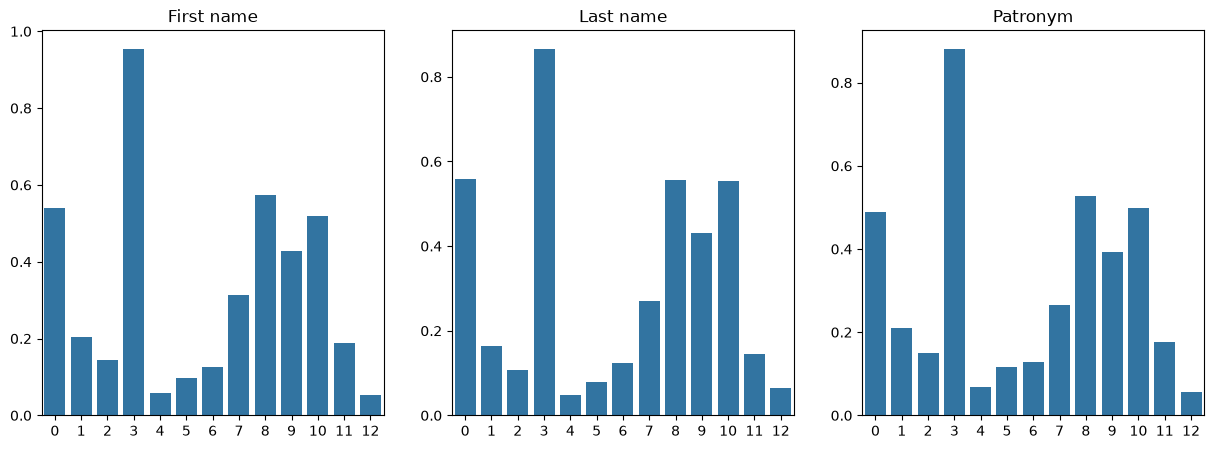

In [23]:
def score_split_cell(
    a, b,
    scorer=rapidfuzz.distance.Levenshtein.normalized_similarity,
    score_cutoff=0,
    sep=" ",
):
    if min(len(a), len(b)) == 0:
        return 0.0
    else:
        return max(
            scorer(candidate, b) for candidate in a.split(sep)
        )


columns_fname_scores_levenshtein = [
    column_match_scores(
        fill_values(col), valid_first_names, scorer=score_split_cell
    )
    for col in page_cols
]
columns_lname_scores_levenshtein = [
    column_match_scores(
        fill_values(col), valid_last_names, scorer=score_split_cell
    )
    for col in page_cols
]
columns_pnym_scores_levenshtein = [
    column_match_scores(
        fill_values(col), valid_patronyms, scorer=score_split_cell
    )
    for col in page_cols
]


fig, axs = plt.subplots(1, 3, figsize=(15, 5))
sns.barplot([np.mean(x) for x in columns_fname_scores_levenshtein], ax=axs[0])
sns.barplot([np.mean(x) for x in columns_lname_scores_levenshtein], ax=axs[1])
sns.barplot([np.mean(x) for x in columns_pnym_scores_levenshtein], ax=axs[2])

axs[0].set_title("First name")
axs[1].set_title("Last name")
axs[2].set_title("Patronym")

<Axes: >

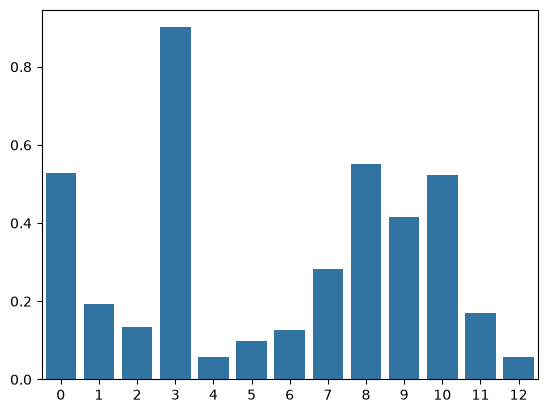

In [24]:
combined_names = (
    np.array([np.mean(x) for x in columns_fname_scores_levenshtein])
    + np.array([np.mean(x) for x in columns_lname_scores_levenshtein])
    + np.array([np.mean(x) for x in columns_pnym_scores_levenshtein])
) / 3

sns.barplot(combined_names)

This not very useful for ruling out columns when trying to find
toponym column, but finding the column for persons name is useful.

## Checking for month and testing other metrics

In [25]:
valid_months = {
    "Tammikuu", "tammikuu", "tammi", "januari",
    "Helmikuu", "helmikuu", "helmi", "februari",
    "Maaliskuu", "maaliskuu", "maalis", "mars",
    "Huhtikuu", "huhtikuu", "huhti", "april",
    "Toukokuu", "toukokuu", "touko", "maj",
    "Kesäkuu", "kesäkuu", "kesä", "juni",
    "Heinäkuu", "heinäkuu", "heinä", "juli",
    "Elokuu", "elokuu", "elo", "augusti",
    "Syyskuu", "syyskuu", "syys", "september",
    "Lokakuu", "lokakuu", "loka", "oktober",
    "Marraskuu", "marraskuu", "marras", "november",
    "Joulukuu", "joulukuu", "joulu", "december",
}

Text(0.5, 1.0, 'Month')

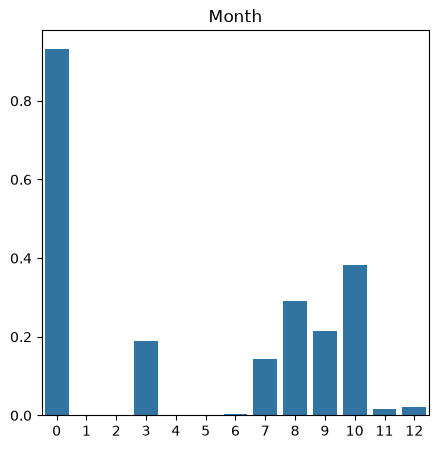

In [26]:
columns_month_scores_levenshtein = [
    column_match_scores(
        fill_values(col), valid_months, scorer=levenshtein_scorer
    )
    for col in page_cols
]

fig, ax = plt.subplots(1, figsize=(5, 5))
sns.barplot([np.mean(x) for x in columns_month_scores_levenshtein], ax=ax)

ax.set_title("Month")

<Axes: >

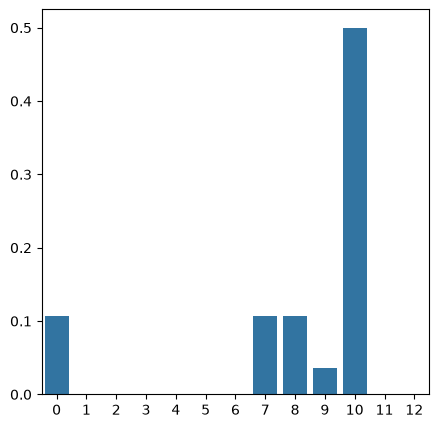

In [27]:
def unique_value_ratio(col):
    return len(
        set(
            map(
                str.lower,
                filter(str.isalpha, fill_values(col))
            )
        )
    ) / len(col)

columns_unique_values_ratio = [
    unique_value_ratio(col) for col in page_cols
]

fig, ax = plt.subplots(1, figsize=(5, 5))
sns.barplot(columns_unique_values_ratio, ax=ax)

## Weighted Levenshtein

In [28]:
from src.levenshtein_c.levenshtein_cython import levenshtein_similarity_weighted
from src import levenshtein_weights
from pathlib import Path

In [29]:
ocr_weights = levenshtein_weights.get_predefined_weights(
    Path(data_dir/"levenshtein_weights/ocr_weights.json")
)
deabbreviate_costs = ocr_weights.pop("deabbreviate_costs")

With weighted Levenshtein: [10  0  8  7  9  3  1 11  2  6  5  4 12]
With Levenshtein: [10  0  8  9  7  3  1 11  2  6  5  4 12]


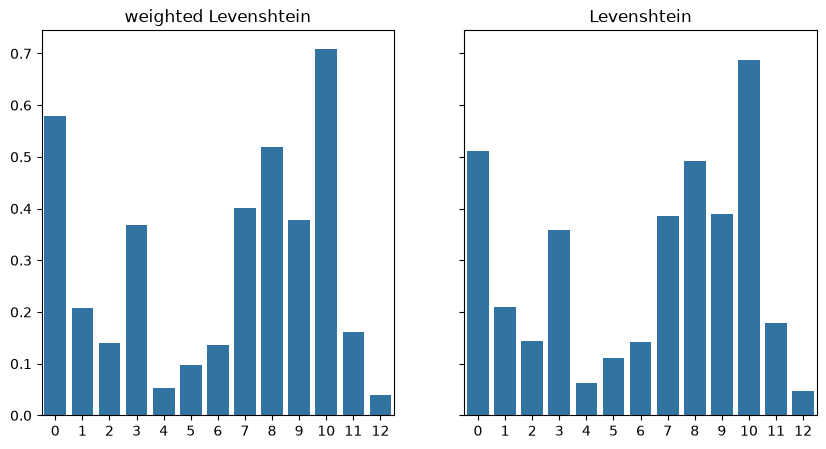

In [30]:
levenshtein_weighted_scorer = levenshtein_similarity_weighted

columns_toponym_scores_levenshtein_weighted = [
    column_match_scores(
        fill_values(col), valid_toponyms, scorer=levenshtein_weighted_scorer,
        scorer_kwargs={
            **ocr_weights
        }
    )
    for col in page_cols
]

column_average_scores_levenshtein_weighted = [
    np.mean(col) for col in columns_toponym_scores_levenshtein_weighted
]
fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
sns.barplot(column_average_scores_levenshtein_weighted, ax=axs[0])
sns.barplot(column_average_scores_levenshtein, ax=axs[1])

axs[0].set_title("weighted Levenshtein")
axs[1].set_title("Levenshtein")

print("With weighted Levenshtein:", np.argsort(column_average_scores_levenshtein_weighted)[::-1])
print("With Levenshtein:", np.argsort(column_average_scores_levenshtein)[::-1])

In [31]:
col = 0
filled_col = fill_values(page_cols[col])
for i, match in enumerate(
    column_match_scores(
        filled_col,
        valid_toponyms,
        scorer=levenshtein_weighted_scorer,
        scorer_kwargs={
            **ocr_weights
        },
        return_scores_only=False,
    )
):
    print(filled_col[i], "->", match)

Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Tammikuun -> ('Tammela', 0.5822222222222222, 1025)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Helmikuu -> ('Haliko', 0.5575, 29)
Maaliskun -> ('Maaninka', 0.6166666666666667, 1452)
Ma

In [32]:
col = 8
filled_col = fill_values(page_cols[col])
for i, match in enumerate(
    column_match_scores(
        filled_col,
        valid_toponyms,
        scorer=levenshtein_weighted_scorer,
        scorer_kwargs={
            **ocr_weights
        },
        return_scores_only=False,
    )
):
    print(filled_col[i], "->", match)

Naimaton -> ('Paemar', 0.5449999999999999, 1554)
Naimaton -> ('Paemar', 0.5449999999999999, 1554)
Naimaton -> ('Paemar', 0.5449999999999999, 1554)
Naimaton -> ('Paemar', 0.5449999999999999, 1554)
Naimaton -> ('Paemar', 0.5449999999999999, 1554)
nainut. -> ('Janak.', 0.49142857142857144, 1329)
nainut. -> ('Janak.', 0.49142857142857144, 1329)
nainut. -> ('Janak.', 0.49142857142857144, 1329)
naimaton -> ('Paemar', 0.5449999999999999, 1554)
naimaton -> ('Paemar', 0.5449999999999999, 1554)
naimaton -> ('Paemar', 0.5449999999999999, 1554)
Nainut -> ('Soini', 0.5166666666666666, 1279)
Nainut -> ('Soini', 0.5166666666666666, 1279)
Leski -> ('Koski', 0.644, 374)
 -> ('Hämeenkyrö', 0.0, 0)
Naimaton -> ('Paemar', 0.5449999999999999, 1554)
Naimaton -> ('Paemar', 0.5449999999999999, 1554)
Nainut -> ('Soini', 0.5166666666666666, 1279)
Nainut -> ('Soini', 0.5166666666666666, 1279)
naimaton -> ('Paemar', 0.5449999999999999, 1554)
nainut -> ('Soini', 0.5166666666666666, 1279)
Naimaton -> ('Paemar', 0.5

In [33]:
col = 9
filled_col = fill_values(page_cols[col])
for i, match in enumerate(
    column_match_scores(
        filled_col,
        valid_toponyms,
        scorer=levenshtein_weighted_scorer,
        scorer_kwargs={
            **ocr_weights
        },
        return_scores_only=False,
    )
):
    print(filled_col[i], "->", match)

Työnteko -> ('Turtola', 0.44000000000000006, 1443)
1 -> ('Hämeenkyrö', 0.0, 0)
1 -> ('Hämeenkyrö', 0.0, 0)
1 -> ('Hämeenkyrö', 0.0, 0)
1 -> ('Hämeenkyrö', 0.0, 0)
Kaupanteko. -> ('Kalajok.', 0.4745454545454545, 32)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtola', 0.44000000000000006, 1443)
Työnteko -> ('Turtol

In [34]:
col = 10
filled_col = fill_values(page_cols[col])
for i, match in enumerate(
    column_match_scores(
        filled_col,
        valid_toponyms,
        scorer=levenshtein_weighted_scorer,
        scorer_kwargs={
            **ocr_weights
        },
        return_scores_only=False,
    )
):
    print(filled_col[i], "->", match)

Kuopioon -> ('Kuopio', 0.75, 181)
Määnika -> ('Maaria', 0.6285714285714286, 680)
Kuopioon -> ('Kuopio', 0.75, 181)
Kuopioon -> ('Kuopio', 0.75, 181)
Kuopioon -> ('Kuopio', 0.75, 181)
Kuinvedell -> ('Kuorevesi', 0.505, 488)
pajunis -> ('Nousis', 0.5514285714285714, 1512)
pajunis -> ('Nousis', 0.5514285714285714, 1512)
pajunis -> ('Nousis', 0.5514285714285714, 1512)
pajunis -> ('Nousis', 0.5514285714285714, 1512)
Maaniska -> ('Maaninka', 0.88875, 1452)
Iisalmalle -> ('Iisalmelta', 0.799, 116)
Iisalmalle -> ('Iisalmelta', 0.799, 116)
Iisalmalle -> ('Iisalmelta', 0.799, 116)
 -> ('Hämeenkyrö', 0.0, 0)
Heipinkiin -> ('Helsinki', 0.628, 670)
Lappeenanta -> ('Lappeenranta', 0.8333333333333334, 1519)
Maaniska -> ('Maaninka', 0.88875, 1452)
Maaniska -> ('Maaninka', 0.88875, 1452)
Maaniska -> ('Maaninka', 0.88875, 1452)
Kuopioon -> ('Kuopio', 0.75, 181)
Maaniska -> ('Maaninka', 0.88875, 1452)
Pihlajavesi -> ('Pihlajavesi', 1.0, 959)
Kunnvesi -> ('Kiuruvesi', 0.6533333333333333, 857)
Iisalmeen ->

## Testing with random pages

Pick some random pages from each book

In [35]:
books = set(x["book"] for x in lines)
book_and_p = [
    (
        book,
        choice(
            list(set(
                y["page_n"]
                for y in filter(lambda x: x["book"] == book, lines)
            ))
        ),
    )
    for book in books
]

In [36]:
chosen_pages = [
    list(
        filter(
            lambda x: (x["page_n"] == page_n and x["book"] == book),
            lines,
        )
    )
    for book, page_n in book_and_p
]

chosen_pages_data = []
for page in chosen_pages:
    chosen_pages_data.append([row["row_data"] for row in page])

chosen_pages_cols = [
    transpose_page_table(page_data) for page_data in chosen_pages_data
]

In [37]:
levenshtein_scorer = rapidfuzz.distance.Levenshtein.normalized_similarity

page_results = []
for page_cols in chosen_pages_cols:
    columns_toponym_scores_levenshtein = [
        column_match_scores(
            fill_values(col), valid_toponyms, scorer=levenshtein_scorer
        )
        for col in page_cols
    ]
    column_average_scores_levenshtein = [
        np.mean(col) for col in columns_toponym_scores_levenshtein
    ]
    page_results.append(column_average_scores_levenshtein)
    toponym_col_idx = np.argmax(column_average_scores_levenshtein)
    print(
        "With Levenshtein: column",
        toponym_col_idx,
        "with score",
        column_average_scores_levenshtein[toponym_col_idx],
    )
    print(*filter(bool, page_cols[toponym_col_idx]))
    print("---")

With Levenshtein: column 11 with score 0.6690323565323566
Kuopio Kuinvesi Karttula. Keitele " " " Kiuruvesi Keitele Maaniska Iljulmi Maaniska Karttula Kuopio Maaniska " " " Riitele Karttula
---
With Levenshtein: column 5 with score 0.8333049886621315
Transport Kuopio Karttula " " " Iisalmi Kiuruvesi Helmyfors Määniga Kuruvesi Iisalmi Kuopio Karttula Wiitasaari Rautalampi Kuopio TisalmiTisalmi Helsingfors Kiuruvesi Kuopio Pihtipudas Aitaja Kiöraari Karttula Kastala Transport
---
With Levenshtein: column 5 with score 0.6852129929592118
Kamkunpää Kärsämäki Iisalmi Lapinlahti " Evijärvi Kiusuuu Haapani Karttula14. Kuopionton lu. an en ut. anm.Virtasari ht. 4 Kuopio,ätal. Hänn Korttula Marrunen " Vibby A Johanis Visalmi Kuopio Finsk. gardi Kfor Karttula " Maaninge Kuopio " " Kiuravesi Mauninga Maanninga Pippola Kuopio Maanissa KarttalaKarttala llykyrka Hfors " Suomjoki Kuopio amma
---
With Levenshtein: column 11 with score 0.8559702749357921
Iisalmi " " Limiukamuuka O.l.n Pyhäjärvi Nurmies 

In [38]:
levenshtein_weighted_scorer = levenshtein_similarity_weighted
page_results_weighted = []
for page_cols in chosen_pages_cols:
    columns_toponym_scores_levenshtein_weighted = [
        column_match_scores(
            fill_values(col),
            valid_toponyms,
            scorer=levenshtein_weighted_scorer,
            scorer_kwargs={**ocr_weights},
        )
        for col in page_cols
    ]
    column_average_scores_levenshtein_weighted = [
        np.mean(col) for col in columns_toponym_scores_levenshtein_weighted
    ]
    page_results_weighted.append(column_average_scores_levenshtein_weighted)
    toponym_col_idx = np.argmax(column_average_scores_levenshtein_weighted)
    print(
        "With weighted Levenshtein: column",
        toponym_col_idx,
        "with score",
        column_average_scores_levenshtein_weighted[toponym_col_idx],
    )
    print(*filter(bool, page_cols[toponym_col_idx]))
    print("---")

With weighted Levenshtein: column 11 with score 0.6653228021978023
Kuopio Kuinvesi Karttula. Keitele " " " Kiuruvesi Keitele Maaniska Iljulmi Maaniska Karttula Kuopio Maaniska " " " Riitele Karttula
---
With weighted Levenshtein: column 5 with score 0.8443296485260772
Transport Kuopio Karttula " " " Iisalmi Kiuruvesi Helmyfors Määniga Kuruvesi Iisalmi Kuopio Karttula Wiitasaari Rautalampi Kuopio TisalmiTisalmi Helsingfors Kiuruvesi Kuopio Pihtipudas Aitaja Kiöraari Karttula Kastala Transport
---
With weighted Levenshtein: column 5 with score 0.6864013444799119
Kamkunpää Kärsämäki Iisalmi Lapinlahti " Evijärvi Kiusuuu Haapani Karttula14. Kuopionton lu. an en ut. anm.Virtasari ht. 4 Kuopio,ätal. Hänn Korttula Marrunen " Vibby A Johanis Visalmi Kuopio Finsk. gardi Kfor Karttula " Maaninge Kuopio " " Kiuravesi Mauninga Maanninga Pippola Kuopio Maanissa KarttalaKarttala llykyrka Hfors " Suomjoki Kuopio amma
---
With weighted Levenshtein: column 11 with score 0.853417561365837
Iisalmi " " Li

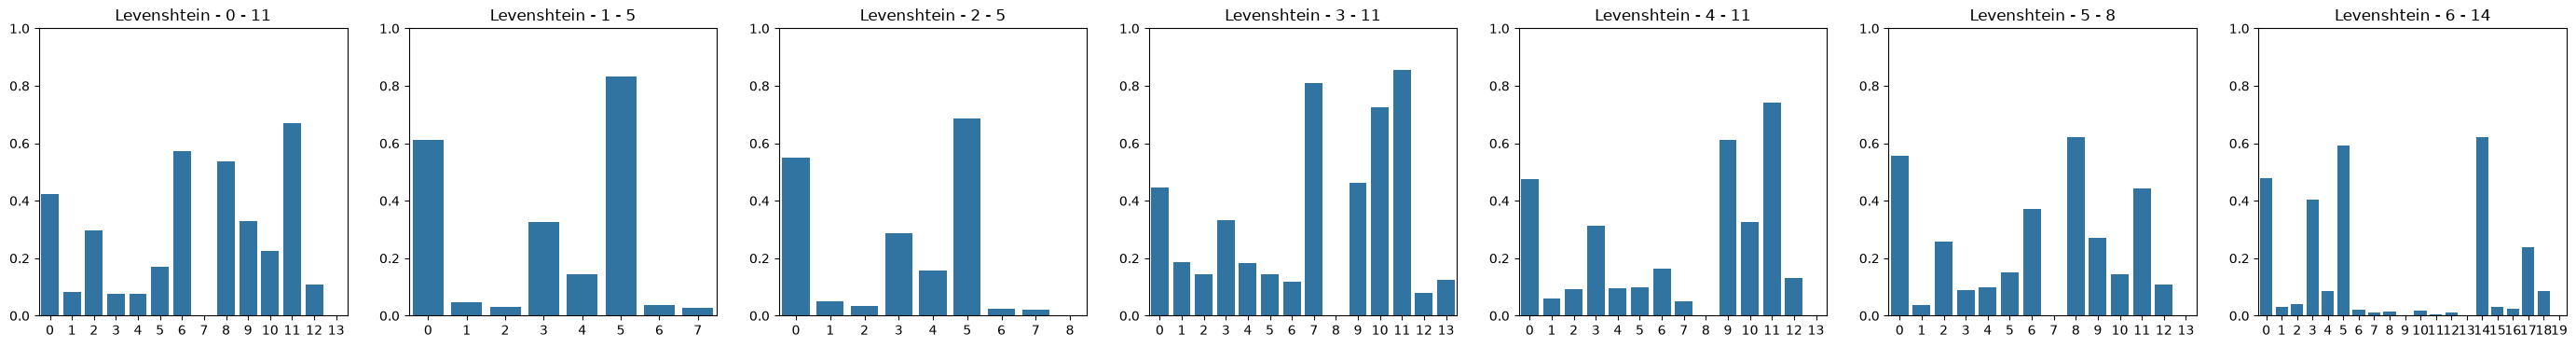

In [39]:
fig, axs = plt.subplots(1, 7, figsize=(35, 4))
for i, (ax, res) in enumerate(zip(axs, page_results)):
    sns.barplot(res, ax=ax)
    ax.set_ylim((0, 1))
    ax.set_title(f"Levenshtein - {i} - {np.argmax(res)}")

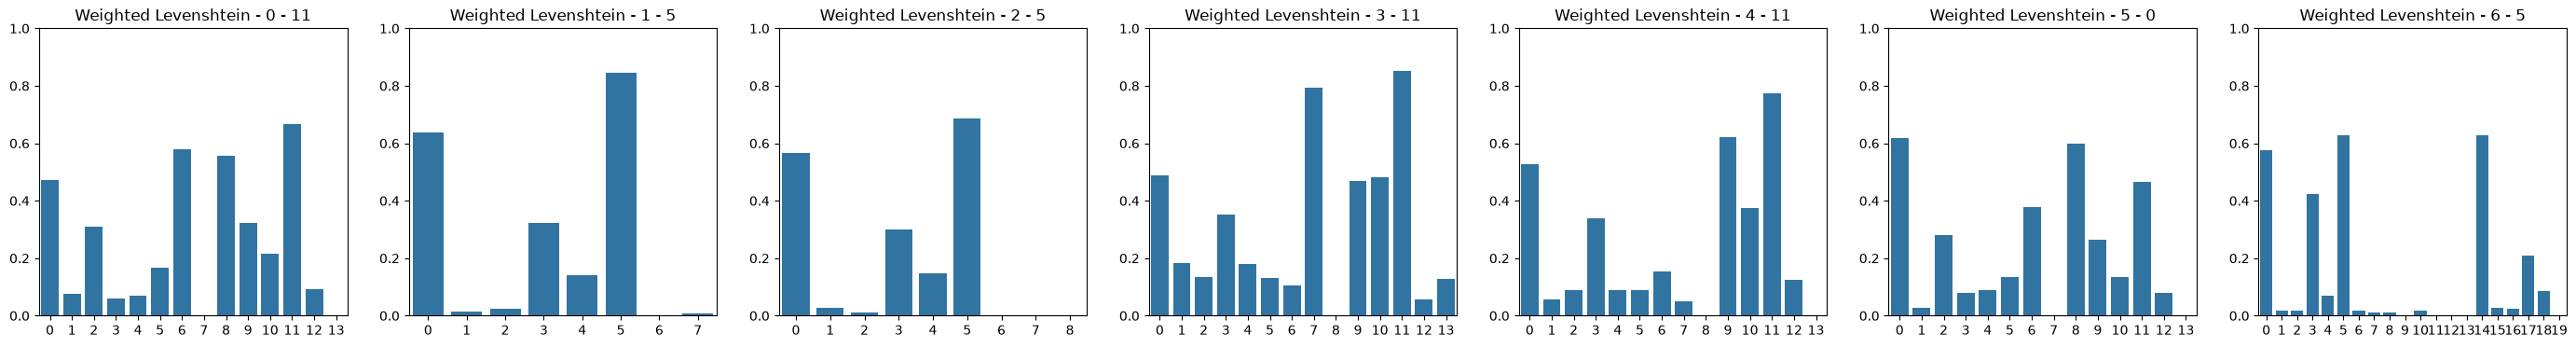

In [40]:
fig, axs = plt.subplots(1, 7, figsize=(35, 4))
for i, (ax, res) in enumerate(zip(axs, page_results_weighted)):
    sns.barplot(res, ax=ax)
    ax.set_ylim((0, 1))
    ax.set_title(f"Weighted Levenshtein - {i} - {np.argmax(res)}")

## Different valid_toponyms data

In [41]:
#with open(data_dir/"kohde_split.txt", "r") as fp:
    #valid_toponyms = set(toponym.replace("\n", "") for toponym in fp.readlines())

#with open(outputs_dir/"json/db_toponyms.json", "r") as fp:
    #valid_toponyms = valid_toponyms.union(
        #set(json.load(fp).keys())
    #)

with open(data_dir/"json/placenames.jsonl", "r") as fp:
    valid_toponyms = set(
        json.loads(line)["spelling"] for line in
        fp
    )

In [ ]:
levenshtein_scorer = rapidfuzz.distance.Levenshtein.normalized_similarity

def column_match_scores(
    column,
    choices,
    scorer=rapidfuzz.distance.Levenshtein.normalized_similarity,
    return_scores_only=True,
    scorer_kwargs=None,
    cache={}
):
    column_match_scores = []
    for cell in column:
        if cache != None:
            cell_cache_result = cache.get(cell)
            if not cell_cache_result:
                cell_score = rapidfuzz.process.extractOne(
                    cell,
                    choices,
                    scorer=scorer,
                    scorer_kwargs=scorer_kwargs
                )
                if cell_score:
                    cache[cell] = cell_score
            else:
                cell_score = cell_cache_result
        else:
            cell_score = rapidfuzz.process.extractOne(
                cell,
                choices,
                scorer=scorer,
                scorer_kwargs=scorer_kwargs
            )
            

        if cell_score:
            column_match_scores.append(
                cell_score[1] if return_scores_only else cell_score
            )
        else:
            column_match_scores.append(
                0.0 if return_scores_only else (None, 0.0, np.nan)
            )

    return column_match_scores


page_results = []
cached_results = {}
for page_cols in chosen_pages_cols:
    columns_toponym_scores_levenshtein = [
        column_match_scores(
            fill_values(col), valid_toponyms, scorer=levenshtein_scorer,
            cache=cached_results
        )
        for col in page_cols
    ]
    column_average_scores_levenshtein = [
        np.mean(col) for col in columns_toponym_scores_levenshtein
    ]
    page_results.append(column_average_scores_levenshtein)
    toponym_col_idx = np.argmax(column_average_scores_levenshtein)
    print(
        "With Levenshtein: column",
        toponym_col_idx,
        "with score",
        column_average_scores_levenshtein[toponym_col_idx],
    )
    print(*filter(bool, page_cols[toponym_col_idx]))
    print("---")

With Levenshtein: column 11 with score 0.7326770451770452
Kuopio Kuinvesi Karttula. Keitele " " " Kiuruvesi Keitele Maaniska Iljulmi Maaniska Karttula Kuopio Maaniska " " " Riitele Karttula
---
With Levenshtein: column 5 with score 0.8561031230674089
Transport Kuopio Karttula " " " Iisalmi Kiuruvesi Helmyfors Määniga Kuruvesi Iisalmi Kuopio Karttula Wiitasaari Rautalampi Kuopio TisalmiTisalmi Helsingfors Kiuruvesi Kuopio Pihtipudas Aitaja Kiöraari Karttula Kastala Transport
---
With Levenshtein: column 0 with score 0.7374821848805102
Löytyväki Sulkana Tuovilanlahti Haalala " Lammassalo Heinämäki Lummassalo KainulahtiHarpaisma Pastbost.Huonamo Tuomilanlahti Vuonumo Jylhä " Past. bole Kantajärvi Harrasabeth Löytymjärvi PastorsbohtPastorsboht Taumo " Harpais " " Pajumäki Sulkava Saarela. " Sulkuna Hautala Tuovilanlahti Taumo Pukam Hautala Pukulmi Lankkala Paum Tuovilanl.
---
With Levenshtein: column 11 with score 0.8457980716601405
Iisalmi " " Limiukamuuka O.l.n Pyhäjärvi Nurmies Helsinki

In [ ]:
levenshtein_weighted_scorer = levenshtein_similarity_weighted
page_results_weighted = []
cached_results = {}
for page_cols in chosen_pages_cols:
    columns_toponym_scores_levenshtein_weighted = [
        column_match_scores(
            fill_values(col),
            valid_toponyms,
            scorer=levenshtein_weighted_scorer,
            scorer_kwargs={**ocr_weights},
            cache=cached_results
        )
        for col in page_cols
    ]
    column_average_scores_levenshtein_weighted = [
        np.mean(col) for col in columns_toponym_scores_levenshtein_weighted
    ]
    page_results_weighted.append(column_average_scores_levenshtein_weighted)
    toponym_col_idx = np.argmax(column_average_scores_levenshtein_weighted)
    print(
        "With weighted Levenshtein: column",
        toponym_col_idx,
        "with score",
        column_average_scores_levenshtein_weighted[toponym_col_idx],
    )
    print(*filter(bool, page_cols[toponym_col_idx]))
    print("---")

With weighted Levenshtein: column 11 with score 0.732026862026862
Kuopio Kuinvesi Karttula. Keitele " " " Kiuruvesi Keitele Maaniska Iljulmi Maaniska Karttula Kuopio Maaniska " " " Riitele Karttula
---
With weighted Levenshtein: column 5 with score 0.8531724773242629
Transport Kuopio Karttula " " " Iisalmi Kiuruvesi Helmyfors Määniga Kuruvesi Iisalmi Kuopio Karttula Wiitasaari Rautalampi Kuopio TisalmiTisalmi Helsingfors Kiuruvesi Kuopio Pihtipudas Aitaja Kiöraari Karttula Kastala Transport
---
With weighted Levenshtein: column 0 with score 0.7259503536236491
Löytyväki Sulkana Tuovilanlahti Haalala " Lammassalo Heinämäki Lummassalo KainulahtiHarpaisma Pastbost.Huonamo Tuomilanlahti Vuonumo Jylhä " Past. bole Kantajärvi Harrasabeth Löytymjärvi PastorsbohtPastorsboht Taumo " Harpais " " Pajumäki Sulkava Saarela. " Sulkuna Hautala Tuovilanlahti Taumo Pukam Hautala Pukulmi Lankkala Paum Tuovilanl.
---
With weighted Levenshtein: column 11 with score 0.8449191402467263
Iisalmi " " Limiukamuu

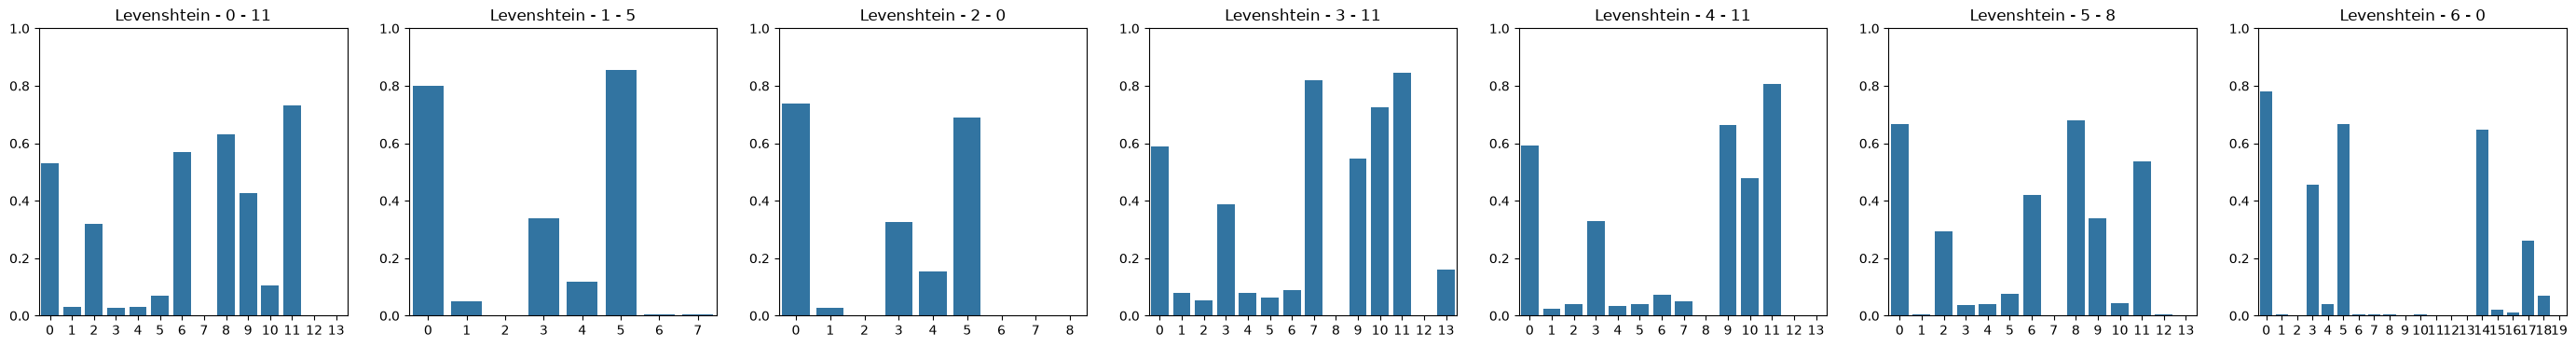

In [44]:
fig, axs = plt.subplots(1, 7, figsize=(35, 4))
for i, (ax, res) in enumerate(zip(axs, page_results)):
    sns.barplot(res, ax=ax)
    ax.set_ylim((0, 1))
    ax.set_title(f"Levenshtein - {i} - {np.argmax(res)}")

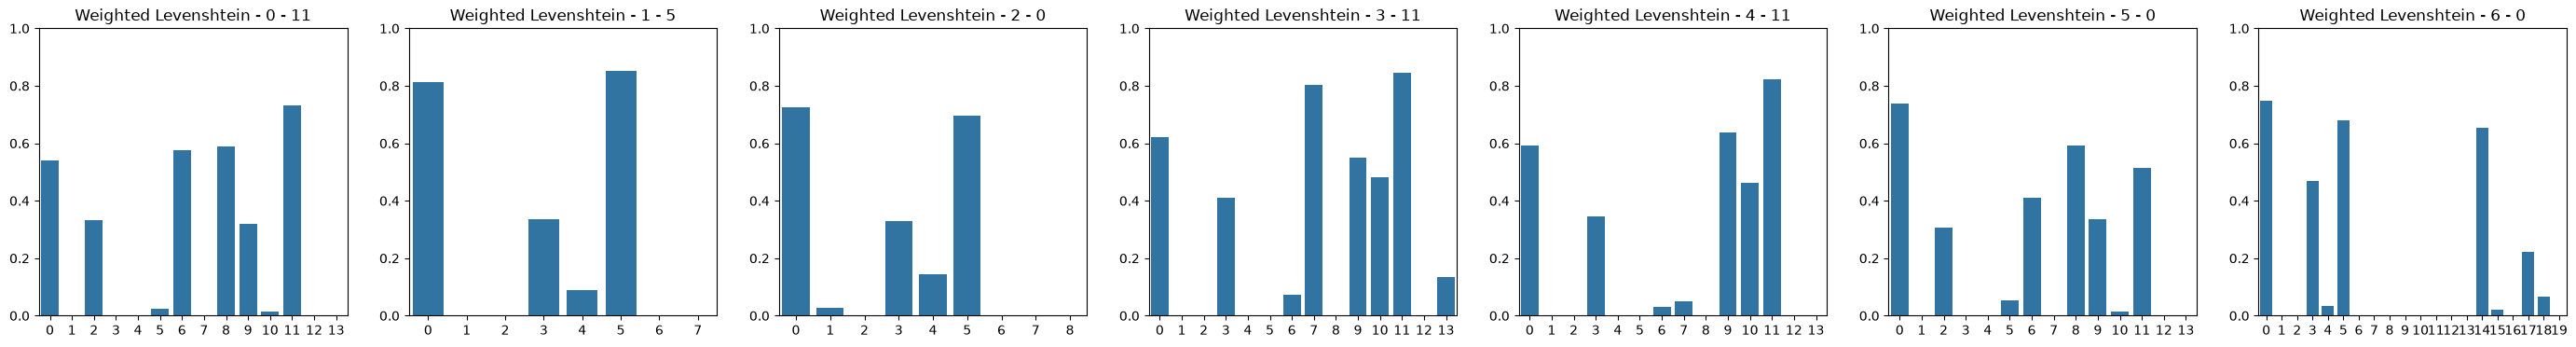

In [45]:
fig, axs = plt.subplots(1, 7, figsize=(35, 4))
for i, (ax, res) in enumerate(zip(axs, page_results_weighted)):
    sns.barplot(res, ax=ax)
    ax.set_ylim((0, 1))
    ax.set_title(f"Weighted Levenshtein - {i} - {np.argmax(res)}")

## Extract multiple placenames

In [46]:
levenshtein_scorer = rapidfuzz.distance.Levenshtein.normalized_similarity

page_results = []
for page_i, page_cols in enumerate(chosen_pages_cols):
    columns_toponym_scores_levenshtein = [
        column_match_scores(
            fill_values(col), valid_toponyms, scorer=levenshtein_scorer
        )
        for col in page_cols
    ]
    column_average_scores_levenshtein = [
        np.mean(col) for col in columns_toponym_scores_levenshtein
    ]
    page_results.append(column_average_scores_levenshtein)

np.argsort(page_results[2])[::-1]

array([0, 5, 3, 4, 1, 2, 8, 7, 6])

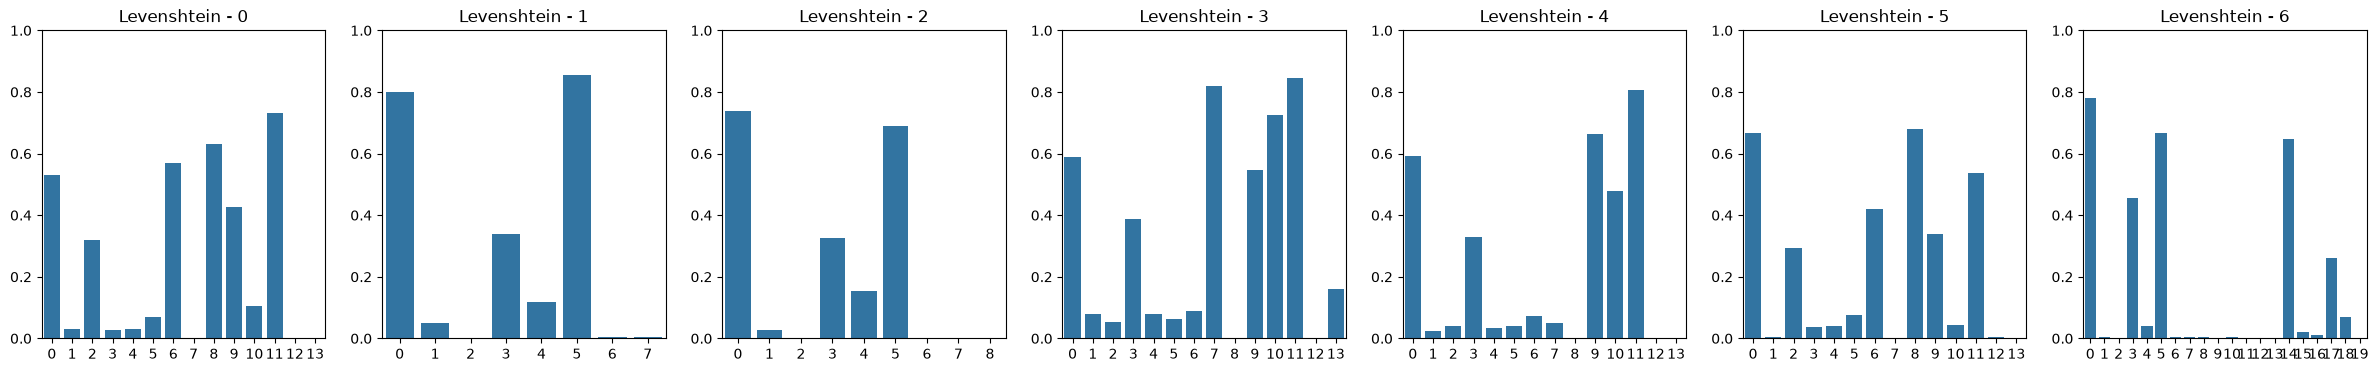

In [47]:
fig, axs = plt.subplots(1, 7, figsize=(30, 4))
for i, (ax, res) in enumerate(zip(axs, page_results)):
    sns.barplot(res, ax=ax)
    ax.set_title(f"Levenshtein - {i}")
    ax.set_ylim(0.0, 1.0)

In [48]:
for page_i, page_cols in enumerate(chosen_pages_cols):
    filled_page_cols = [fill_values(col) for col in page_cols]
    for row_i, row in enumerate(transpose_page_table(filled_page_cols)):
        page_metadata = chosen_pages[page_i][0]
        page_cols_categorized = page_metadata["row_columns_categorized"]
        page_cols_original = page_metadata["row_columns"]
        page_metadata_suggested_toponyms = page_metadata[
            "possibly_related_toponyms"
        ]

        column_sorted_most_likely_toponyms = np.argsort(page_results[page_i])[
            ::-1
        ]

        num_place_cols_categorized = (
            page_cols_categorized.count("place")
            + page_cols_categorized.count("source")
            + page_cols_categorized.count("destination")
        )
        if num_place_cols_categorized > 0:
            print(
                [
                    (
                        row[found],
                        suggested[2],
                        page_cols_original[suggested[0]],
                    )
                    for found, suggested in zip(
                        sorted(column_sorted_most_likely_toponyms[
                            :num_place_cols_categorized
                        ]),
                        page_metadata_suggested_toponyms,
                    )
                ],
                num_place_cols_categorized
            )

[('Naimaton', 'place', '(syntymä)paikka'), ('Kuopio', 'place', '(muuttokirjan)paikka')] 2
[('Naimaton', 'place', '(syntymä)paikka'), ('Kuinvesi', 'place', '(muuttokirjan)paikka')] 2
[('Naimaton', 'place', '(syntymä)paikka'), ('Karttula.', 'place', '(muuttokirjan)paikka')] 2
[('Naimaton', 'place', '(syntymä)paikka'), ('Keitele', 'place', '(muuttokirjan)paikka')] 2
[('Naimat.', 'place', '(syntymä)paikka'), ('Keitele', 'place', '(muuttokirjan)paikka')] 2
[('Naimat.', 'place', '(syntymä)paikka'), ('Keitele', 'place', '(muuttokirjan)paikka')] 2
[('Leski', 'place', '(syntymä)paikka'), ('Keitele', 'place', '(muuttokirjan)paikka')] 2
[('Naimaton', 'place', '(syntymä)paikka'), ('Kiuruvesi', 'place', '(muuttokirjan)paikka')] 2
[('Naimaton', 'place', '(syntymä)paikka'), ('', 'place', '(muuttokirjan)paikka')] 2
[('Naimaton', 'place', '(syntymä)paikka'), ('Keitele', 'place', '(muuttokirjan)paikka')] 2
[('Naimaton', 'place', '(syntymä)paikka'), ('Maaniska', 'place', '(muuttokirjan)paikka')] 2
[('Nai